<a href="https://colab.research.google.com/github/IsmaeelDhikr/IsmaeelDhikr/blob/main/EIoT_QSVM_workshop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on Quantum Machine Learning: from quantum kernels to hardware

**Africa Quantum Consortium × EigenOrbit** · 90-minute workshop

In this notebook you will learn about quantum support vector machines. You will build a quantum-kernel classifier, change the quantum model and watch what happens, benchmark it honestly against classical methods, move the same circuit onto real IBM hardware, and finish with an open problem: designing kernels that suit two different hardware architectures.

Everything runs on **eigenkit**, a Python library where a circuit is a value you can hand to any backend with one `provider=` argument and models follow the scikit-learn estimator contract.

**Exercises** are marked ⭐ (do it in the session), ⭐⭐ (if you have time) and ⭐⭐⭐ (open challenge, take it home). Look for `# TODO`.

## 0. Setup and the software stack

Install once, before the session, in Python 3.12 or 3.13 (the exact line will be confirmed in the setup email):

```bash
pip install "eigenkit[qml,qiskit,iqm,qulacs,benchmark,viz]"
```

In [1]:
pip install "eigenkit[qml,qiskit,iqm,qulacs,benchmark,viz]"

INFO: pip is looking at multiple versions of qiskit-ibm-runtime to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 525.1/525.1 kB 5.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 29.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 33.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 68.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 73.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 53.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 13.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 55.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 665.2/665.2 kB 31.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 76.2 MB/s  0:00:00
  Attempting uninstall: python-dateutil
    Found existing installation: python-dateutil 2.9.0

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, StandardScaler
from sklearn.svm import SVC

import eigenkit
from eigenkit import QSVC, QuantumKernel, align_kernel
from eigenkit.configs import IQMConfig, QiskitRuntimeConfig
from eigenkit.core.provider import registered_names
from eigenkit.datasets import load_dataset

# compare() notes that a Pipeline holding a QSVC is not a pure-scikit-learn
# model. That is expected here.
warnings.filterwarnings("ignore", message=".*non-sklearn components.*")

print("eigenkit", eigenkit.__version__)
print("providers available on this machine:", registered_names())

eigenkit 1.3.0
providers available on this machine: ['iqm', 'numpy', 'qiskit', 'qiskit-aer', 'qiskit-aer-mps', 'qulacs']


### Save your IBM Quantum account (once, before the session)

1. Sign up for the free **Open Plan** at [quantum.cloud.ibm.com](https://quantum.cloud.ibm.com).
2. On the dashboard, create an **API key** and copy it.
3. Open **Instances** and copy the **CRN** of your Open Plan instance (it starts with `crn:v1:`).
4. Run this once in Python, with your key and CRN:

```python
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token="YOUR_API_KEY",
    instance="YOUR_INSTANCE_CRN",
    set_as_default=True,
    overwrite=True,
)
```

The key and the instance are stored on your computer (`~/.qiskit/qiskit-ibm.json`), and every IBM call in this notebook uses them. The cell below checks the account and lists the devices your instance can use. Parts 1–4 do not need it, and Part 5 has a fallback.

In [2]:
# Do not run the following cells until you get to "Test cells end"
# They are steps to check and debug the cause of "cancelled workload on IBM Quantum"

In [ ]:
# Chwch submitted work status
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

# Retrieve your submitted workload
job = service.job("dc13cc2nj2vs73der8vg")

# Examine job information
print("Job ID:", job.job_id())
print("Status:", job.status())
print("Backend:", job.backend())

# Check cancellation and failure information
print("Cancelled:", job.cancelled())
print("Error:", job.error_message())

Job ID: dc13cc2nj2vs73der8vg
Status: ERROR
Backend: <IBMBackend('ibm_kingston')>
Cancelled: False
Error: Job dc13cc2nj2vs73der8vg ran longer than maximum execution time. Job was cancelled:



In [ ]:
print("Job status:", job.status())
print("Job ID:", job.job_id())
print("Job metrics:", job.metrics())
print("Error message:", job.error_message())

Job status: ERROR
Job ID: dc13cc2nj2vs73der8vg
Job metrics: {'caller': 'qiskit_ibm_runtime~sampler.py', 'qiskit_version': 'qiskit_ibm_runtime-0.45.1,qiskit-2.1.2*,qiskit_aer-0.17.2', 'timestamps': {'created': '2026-11-22T00:24:16.656874Z', 'finished': '2026-11-22T12:42:23.100979Z', 'running': '2026-11-22T00:27:23.003449Z'}, 'bss': {'seconds': 0}, 'usage': {'quantum_seconds': 0, 'seconds': 0, 'status': 'pending'}}
Error message: Job dc13cc2nj2vs73der8vg ran longer than maximum execution time. Job was cancelled:



In [ ]:
print("Job ID:", job.job_id())
print("Status:", job.status())
print("Backend:", job.backend())
print("Cancelled:", job.cancelled())

print("\nError message:")
print(job.error_message())

print("\nMetrics:")
print(job.metrics())

Job ID: dc13cc2nj2vs73der8vg
Status: ERROR
Backend: <IBMBackend('ibm_kingston')>
Cancelled: False

Error message:
Job dc13cc2nj2vs73der8vg ran longer than maximum execution time. Job was cancelled:


Metrics:
{'caller': 'qiskit_ibm_runtime~sampler.py', 'qiskit_version': 'qiskit_ibm_runtime-0.45.1,qiskit-2.1.2*,qiskit_aer-0.17.2', 'timestamps': {'created': '2026-11-22T00:24:16.656874Z', 'finished': '2026-11-22T12:42:23.100979Z', 'running': '2026-11-22T00:27:23.003449Z'}, 'bss': {'seconds': 0}, 'usage': {'quantum_seconds': 0, 'seconds': 0, 'status': 'pending'}}


In [ ]:
# 1. Actual usage
print("Final usage:", job.usage())

# 2. Intermediate usage, if available
#print("Partial usage:", job.usage(partial=True))

# 3. Backend operational status
backend = job.backend()
status = backend.status()

print("Backend operational:", status.operational)
print("Pending jobs:", status.pending_jobs)
print("Backend status:", status.status_msg)

Final usage: 0
Backend operational: True
Pending jobs: 0
Backend status: active


In [ ]:
from qiskit import QuantumCircuit, transpile
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

# Connect to IBM Quantum
service = QiskitRuntimeService()

# Select backend
backend = service.backend("ibm_kingston")

# Construct circuit
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

# Transpile to backend ISA
isa_qc = transpile(
    qc,
    backend=backend,
    optimization_level=1,
    seed_transpiler=42
)

# Inspect transpiled circuit
print("Original circuit:")
print(qc)

print("\nTranspiled circuit:")
print(isa_qc)

print("\nCircuit depth:", isa_qc.depth())
print("Circuit operations:", isa_qc.count_ops())

# Submit ISA-compliant circuit
sampler = SamplerV2(mode=backend)

job_test = sampler.run(
    [isa_qc],
    shots=100
)

print("\nJob ID:", job_test.job_id())
print("Job status:", job_test.status())

Original circuit:
        ┌───┐      ░ ┌─┐   
   q_0: ┤ H ├──■───░─┤M├───
        └───┘┌─┴─┐ ░ └╥┘┌─┐
   q_1: ─────┤ X ├─░──╫─┤M├
             └───┘ ░  ║ └╥┘
meas: 2/══════════════╩══╩═
                      0  1 

Transpiled circuit:
global phase: 3π/4
         ┌─────────┐┌────┐┌─────────┐                                ░ ┌─┐   
q_0 -> 0 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├─■──────────────────────────────░─┤M├───
         ├─────────┤├────┤├─────────┤ │ ┌─────────┐┌────┐┌─────────┐ ░ └╥┘┌─┐
q_1 -> 1 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├─■─┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├─░──╫─┤M├
         └─────────┘└────┘└─────────┘   └─────────┘└────┘└─────────┘ ░  ║ └╥┘
 meas: 2/═══════════════════════════════════════════════════════════════╩══╩═
                                                                        0  1 

Circuit depth: 8
Circuit operations: OrderedDict({'rz': 6, 'sx': 3, 'measure': 2, 'cz': 1, 'barrier': 1})

Job ID: dc1fbgqnj2vs73df985g
Job status: QUEUED


In [ ]:
import time

while job_test.status() not in [
    "DONE", "ERROR", "CANCELLED"
]:
    print("Current status:", job_test.status())
    time.sleep(10)

status = job_test.status()

print("Final status:", status)

if status == "DONE":

    result = job_test.result()

    counts = result[0].data.meas.get_counts()

    print("Measurement results:", counts)

else:
    print("Error:", job_test.error_message())

Final status: DONE
Measurement results: {'11': 48, '00': 51, '01': 1}


In [ ]:
print("Test job usage:", job_test.usage())
print("Test job metrics:", job_test.metrics())

Test job usage: 2
Test job metrics: {'caller': 'qiskit_ibm_runtime~sampler.py', 'qiskit_version': 'qiskit_ibm_runtime-0.47.0,qiskit-2.6.2*,qiskit_aer-0.18.2,qiskit_experiments-0.12.0,qiskit_optimization-0.7.0,qiskit_addon_utils-0.2.0', 'timestamps': {'created': '2026-11-22T14:01:39.744746Z', 'finished': '2026-11-22T14:01:46.065297Z', 'running': '2026-11-22T14:01:41.603089Z'}, 'bss': {'seconds': 2}, 'usage': {'quantum_seconds': 2, 'seconds': 2, 'status': 'complete'}}


# Test cells end.
# The above cells checked and debugged "cancelled submitted workload on IBM Quantum"
# Continue on the subsequent cells

In [3]:
from qiskit_ibm_runtime import QiskitRuntimeService

BACKEND_NAME = "least_busy"
HAVE_IBM = bool(QiskitRuntimeService.saved_accounts())

if HAVE_IBM:
    service = QiskitRuntimeService()  # your saved account and instance
    devices = service.backends(operational=True, simulator=False)
    print("Your instance can use:", ", ".join(sorted(f"{b.name} ({b.num_qubits} qubits)" for b in devices)))
    if BACKEND_NAME == "least_busy":  # pick once, so every cell below uses the same device
        BACKEND_NAME = service.least_busy(operational=True, simulator=False).name
    print("This notebook will use:", BACKEND_NAME)
else:
    print("No saved IBM account found. Parts 1-4 run locally; Part 5 has a fallback.")

Your instance can use: ibm_fez (156 qubits), ibm_kingston (156 qubits), ibm_marrakesh (156 qubits)
This notebook will use: ibm_fez


## 1. From classical SVM to quantum kernels

A **support vector machine** (SVM) finds the hyperplane that separates two classes with the largest margin. Real data is rarely linearly separable, so SVMs use the *kernel trick*: they only ever need inner products of the data mapped into a feature space,

$$
K(x_i, x_j) = \langle\phi(x_i), \phi(x_j)\rangle ,
$$

and never the map $\phi$ itself.

<div align="center">
<img src="https://github.com/laiadc/QML/blob/main/QSVM%20tutorial/KernelSVM.PNG?raw=1" alt="Kernel Support Vector Machines" width="600"/>
</div>

A **quantum kernel** uses a quantum circuit as the feature map. A data point is encoded into a state,

$$
x \longrightarrow |\psi(x)\rangle = U(x)\,|0\rangle^{\otimes n},
$$

and the kernel is the overlap of two such states,

$$
K(x_i, x_j) = |\langle\psi(x_i)|\psi(x_j)\rangle|^2 = \big|\langle 0|^{\otimes n}\, U^\dagger(x_j)\, U(x_i)\,|0\rangle^{\otimes n}\big|^2 .
$$

On hardware this is measured directly: run $U(x_i)$ followed by $U^\dagger(x_j)$ and count how often every qubit comes back in $|0\rangle$.

<div align="center">
<img src="https://github.com/laiadc/QML/blob/main/QSVM%20tutorial/QSVM.PNG?raw=1" alt="Quantum enhanced Support Vector Machines" width="600"/>
</div>

The pipeline for the rest of the session:

**data → encoding → quantum circuit → measurement → kernel matrix → classical SVM**

The SVM itself stays classical. Every design decision that makes this "quantum" lives in the encoding and the circuit, which is why those are what you will change.

### The data

The Wisconsin breast-cancer dataset: 569 tumours, 30 measured features, labelled malignant or benign. `load_dataset` returns a train / validation / test split; we keep 70 % for training, 10 % for validation and 20 % for the final test.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

# load from google drive
import pandas as pd
bin_eiot = pd.read_csv("/content/drive/MyDrive/bin_eiot.csv")

Mounted at /content/drive


In [ ]:
import pandas as pd

bin_eiot = pd.read_csv("G:\My Drive\bin_eiot.csv")#("/content/drive/MyDrive/bin_eiot.csv")

In [5]:
bin_eiot.shape

(152032, 35)

In [6]:
# to train with default features (35) before correlation to 10
bin_eiotsample = bin_eiot.sample(n=1000, random_state=42) # to show distribution ratio. Not yet balance

# Separate the two classes
normal_def = bin_eiot[bin_eiot['Attack_label'] == 0]
attack_def = bin_eiot[bin_eiot['Attack_label'] == 1]

# Randomly select 500 samples from each class
norm_defsample = normal_def.sample(n=500, random_state=42)
att_defsample = attack_def.sample(n=500, random_state=42)

# Combine and shuffle
bal_eiot = pd.concat([norm_defsample, att_defsample]) # balanced ratio distribution
#bal_eiot = bal_eiot.sample(frac=1, random_state=42).reset_index(drop=True)

# Separate features and target
#X = balanced_def.drop(columns=['Attack_label'])
#y = balanced_def['Attack_label']

# Verify
print("sampling: ", bal_eiot.shape)
#print("Balanced dataset shape:", def_X.shape)
#print("\nClass distribution:")
#print(def_y.value_counts())

sampling:  (1000, 35)


In [7]:
from sklearn.model_selection import train_test_split

# Separate features and target
# Assuming the last column is the target based on the class counts context
X = bal_eiot.iloc[:, :-1]
y = bal_eiot.iloc[:, -1]

# Split into 70% train and 30% temp (validation + test)
X_train_raw, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Split the temp 30% into 10% validation and 20% test (relative to original dataset)
# 1/3 of 30% is 10%, 2/3 of 30% is 20%
X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_temp, y_temp, test_size=2/3, random_state=42, stratify=y_temp)

print(f"Train set: {X_train_raw.shape}, {y_train.shape}")
print(f"Validation set: {X_val_raw.shape}, {y_val.shape}")
print(f"Test set: {X_test_raw.shape}, {y_test.shape}")

Train set: (700, 34), (700,)
Validation set: (100, 34), (100,)
Test set: (200, 34), (200,)


In [8]:
#data = load_dataset("breast_cancer_wisconsin", test_size=0.2, validation_size=0.1, random_state=42)
#X_train_raw, y_train = data["X_train"], data["y_train"]
#X_val_raw, y_val = data["X_val"], data["y_val"]
#X_test_raw, y_test = data["X_test"], data["y_test"]

CLASS_NAMES = {0: "malignant", 1: "benign"}  # scikit-learn's encoding of this dataset
print("train / val / test:", len(y_train), len(y_val), len(y_test))
print("class counts in train:", {CLASS_NAMES[c]: int(n) for c, n in enumerate(np.bincount(y_train))})

train / val / test: 700 100 200
class counts in train: {'malignant': 350, 'benign': 350}


### From 30 features to a few qubits

Each feature will become a rotation angle on one qubit, so 30 features would mean 30 qubits, far beyond what we can simulate quickly. We compress with **principal component analysis** (PCA), which keeps the directions of largest variance.

The features have very different units (an *area* is in the thousands, a *smoothness* below 1), so we standardise first. We will look at the total variance explained by the components.

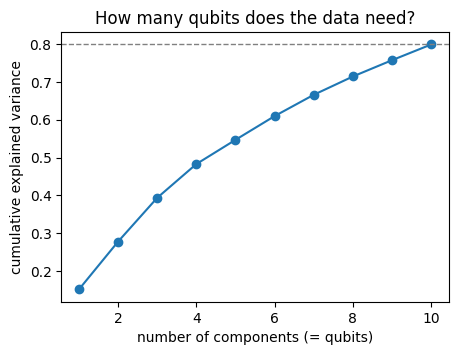

[0.151 0.278 0.393 0.483 0.547 0.61  0.666 0.715 0.758 0.799]


In [9]:
pca_full = make_pipeline(StandardScaler(), PCA(n_components=10)).fit(X_train_raw)
cumulative = np.cumsum(pca_full[-1].explained_variance_ratio_)

plt.figure(figsize=(5, 3.5))
plt.plot(range(1, 11), cumulative, marker="o")
plt.axhline(0.8, color="grey", ls="--", lw=1)
plt.xlabel("number of components (= qubits)")
plt.ylabel("cumulative explained variance")
plt.title("How many qubits does the data need?")
plt.show()
print(np.round(cumulative, 3))

### Full preprocessing pipeline

Now that we've seen how to reduce the number of qubits of our system, let's define the whole pre-processing pipeline. First, we will standarize the data, then retrieve the top PCA components. Finally, we will re-scale the features to an angle domain. Notice that each feature will become a rotation angle, so the range we scale it to **is** part of the quantum model: it sets how far apart two samples end up in Hilbert space (the kernel's *bandwidth*). We scale every principal component to $[0, \pi]$ once, here, and use the scaled data everywhere below.

Why $\pi$ and not $2\pi$? $R_X(2\pi) = -I$, so with a $2\pi$ range the smallest and the largest value of a feature are encoded as the *same* state.

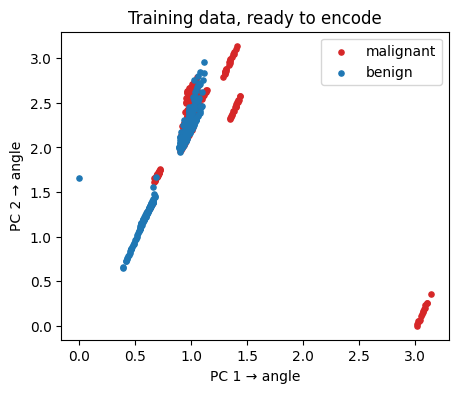

In [10]:
N_QUBITS = 2


def make_preprocessing(n_components=N_QUBITS, angle_range=np.pi):
    """Standardise, project onto the leading principal components, and rescale
    to rotation angles in [0, angle_range]. Fitted on training data only."""
    return make_pipeline(
        StandardScaler(),
        PCA(n_components=n_components),
        MinMaxScaler((0.0, angle_range)),
        # validation / test points can land slightly outside the training range. clip them:
        FunctionTransformer(np.clip, kw_args={"a_min": 0.0, "a_max": angle_range}),
    )


preprocessing = make_preprocessing().fit(X_train_raw)
X_train, X_val, X_test = (preprocessing.transform(X) for X in (X_train_raw, X_val_raw, X_test_raw))

plt.figure(figsize=(5, 4))
for c, colour in ((0, "tab:red"), (1, "tab:blue")):
    plt.scatter(*X_train[y_train == c].T, s=14, c=colour, label=CLASS_NAMES[c])
plt.xlabel("PC 1 → angle")
plt.ylabel("PC 2 → angle")
plt.title("Training data, ready to encode")
plt.legend()
plt.show()

## 2. Build and run a quantum-kernel experiment

The `QuantumKernel` package performs the whole construction circuit: the feature map $U(x)$, the adjoint circuit $U(x_i)\,U^\dagger(x_j)$ (derived automatically) and the evaluation of the Gram matrix. We start with the simplest map, angle encoding (`feature_map="Angle"`): one $R_X(x_q)$ rotation per qubit.

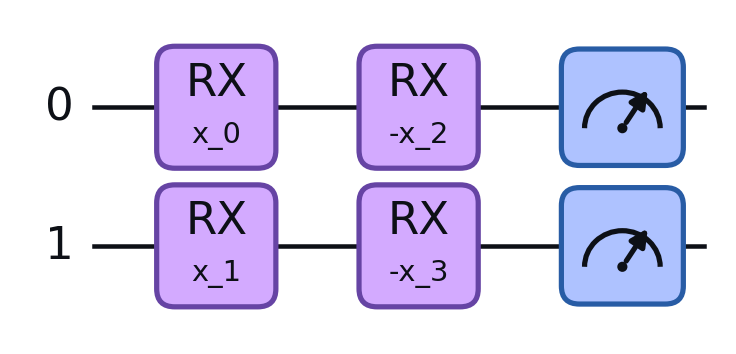

In [11]:
kernel = QuantumKernel(n_features=N_QUBITS, feature_map="Angle", reps=1)
fig, ax = kernel.draw_mpl(inversion=True, style="eigen")  # what a QPU runs for one kernel entry
fig

On a simulator the kit does not run one adjoint circuit per pair: it evolves each $U(x)|0\rangle$ once and reads every overlap off a single matrix product, $O(N)$ circuit evaluations instead of $O(N^2)$, with the same numbers. On hardware there is no statevector, and it falls back to the adjoint circuit, all pairs in one job (Part 5). Let's visualize the kernel matrix:

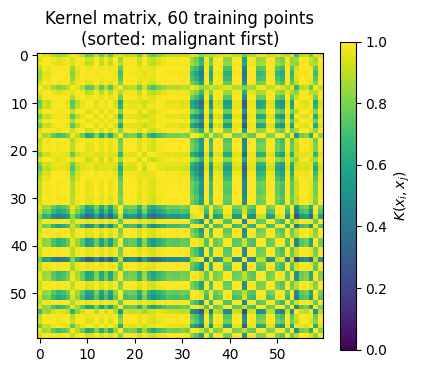

In [12]:
order = np.argsort(y_train[:60], kind="stable")
K_demo = kernel.compute_kernel_matrix(X_train[:60][order])

plt.figure(figsize=(4.6, 4))
plt.imshow(K_demo, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="$K(x_i, x_j)$")
plt.title("Kernel matrix, 60 training points\n(sorted: malignant first)")
plt.show()

### Train the SVM

`QSVC` is a scikit-learn classifier: `fit`, `predict`, `score`. Pass it the kernel and it computes the training Gram matrix, fits a classical SVM on it, and computes test-vs-train kernels when predicting.

In [13]:
qsvc = QSVC(kernel=kernel).fit(X_train, y_train)
print(f"validation accuracy: {qsvc.score(X_val, y_val):.3f}")
print(f"test accuracy:       {qsvc.score(X_test, y_test):.3f}")

validation accuracy: 0.610
test accuracy:       0.575


Let's visualize the predictions:

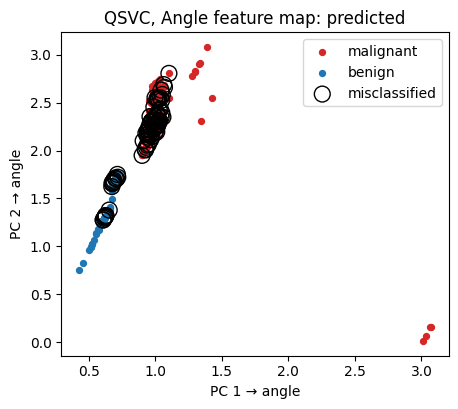

In [14]:
def plot_predictions(model, X, y, title):
    """Predicted labels in the 2-D angle space; misclassified points circled."""
    predicted = model.predict(X)
    fig, ax = plt.subplots(figsize=(5, 4.2))
    for c, colour in ((0, "tab:red"), (1, "tab:blue")):
        ax.scatter( *X[predicted == c, :2].T, s=18, c=colour,label=CLASS_NAMES[c])
    wrong = predicted != y
    ax.scatter(*X[wrong, :2].T, s=130, facecolors="none", edgecolors="k", label="misclassified")
    ax.set_title(f"{title}: predicted")
    ax.set_xlabel("PC 1 → angle")
    ax.set_ylabel("PC 2 → angle")
    ax.legend(loc="upper right")
    plt.show()


plot_predictions(qsvc, X_test, y_test, "QSVC, Angle feature map")

### Cross-validation

It is a scikit-learn estimator, so it composes with everything in scikit-learn. You can put the preprocessing and the quantum model in one `Pipeline` and cross-validate it.

In [15]:
X_trainval_raw = np.vstack([X_train_raw, X_val_raw])
y_trainval = np.concatenate([y_train, y_val])

pipeline = make_pipeline(make_preprocessing(), QSVC(feature_map="Angle", reps=1))
scores = cross_val_score(pipeline, X_trainval_raw, y_trainval, cv=5)
print("5-fold CV accuracy:", np.round(scores, 3), "mean", round(scores.mean(), 3))

5-fold CV accuracy: [0.625 0.581 0.581 0.6   0.644] mean 0.606


### The two built-in feature maps

`QuantumKernel` and `QSVC` come with two maps. `"Angle"` is the one above: one rotation per feature and no entanglement (`reps` repeats it, alternating $R_X$ and $R_Z$). `"AngleCNOT"` adds a ladder of CNOTs between repetitions, so from `reps=2` on the qubits are entangled; with `reps=1` it is identical to `"Angle"`. Here it is on 3 qubits:

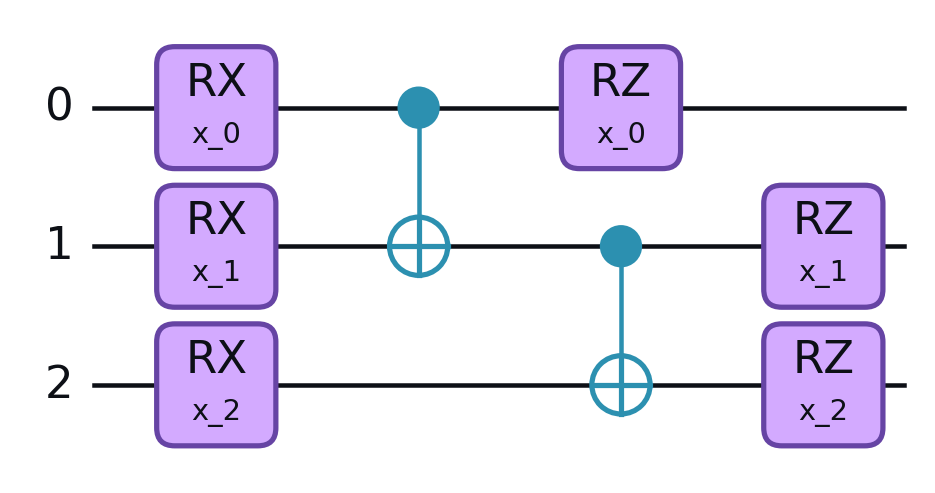

In [16]:
angle_cnot = QuantumKernel(n_features=3, feature_map="AngleCNOT", reps=2)
fig, ax = angle_cnot.draw_mpl(style="eigen")
fig

### ⭐ Exercise 2.1 — tune the model with cross-validation

Use `GridSearchCV` on the same pipeline to search over the number of qubits (the PCA components), the feature map (options `Angle` and `AngleCNOT`) and its depth (`reps`). Every combination is scored by 5-fold cross-validation on the training + validation data. Which knob matters most? Does more depth help? Finish with the test accuracy of the best model.

scikit-learn names a parameter inside a pipeline `<step>__<parameter>`: the preprocessing pipeline is the step `pipeline` (so the number of components is `pipeline__pca__n_components`), and the quantum model is `qsvc` (`qsvc__feature_map`, `qsvc__reps`).

In [17]:
search = GridSearchCV(
    make_pipeline(make_preprocessing(), QSVC()),
    param_grid={
        # TODO: the number of qubits ("pipeline__pca__n_components"), the feature map
        # ("qsvc__feature_map": "Angle" or "AngleCNOT") and its depth ("qsvc__reps")
        "pipeline__pca__n_components": [4, 6, 8, 10],
        "qsvc__feature_map": ["Angle", "AngleCNOT"],
        "qsvc__reps": [1, 2]
    },
    cv=5,
).fit(X_trainval_raw, y_trainval)

print("best:", search.best_params_, f"CV accuracy {search.best_score_:.3f}")
# TODO: print the test accuracy of the best model: search.score(X_test_raw, y_test)
print(f"test accuracy of the best model: {search.score(X_test_raw, y_test):.3f}")

best: {'pipeline__pca__n_components': 10, 'qsvc__feature_map': 'Angle', 'qsvc__reps': 2} CV accuracy 0.718


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


test accuracy of the best model: 0.685


### ⭐ Exercise 2.2 — shots

On hardware, every kernel entry is *estimated* from a finite number of shots $S$. Rebuild the kernel on a shot-based simulator (Qiskit Aer, driven through the same IBM Runtime interface you will use on hardware) and measure how the error of $K$ falls with $S$. What slope do you expect on a log-log plot?

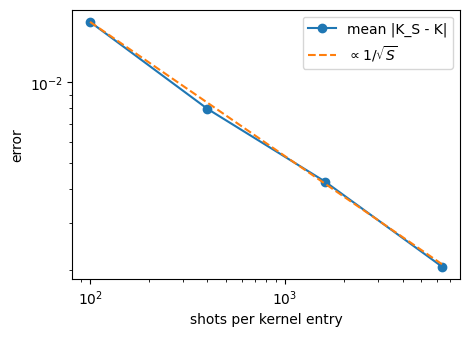

In [18]:
from qiskit_aer import AerSimulator

X_small = X_train[:20]
K_exact = kernel.compute_kernel_matrix(X_small)
shots_list = [100, 400, 1600, 6400]
errors = []
for shots in shots_list:
    # TODO: the same "Angle" kernel, but on
    #   provider = QiskitRuntimeConfig(backend_instance=AerSimulator(), primitive="sampler", shots=shots)
    # then append the mean absolute error against K_exact.
    provider = QiskitRuntimeConfig(
        backend_instance=AerSimulator(),
        primitive="sampler",
        shots=shots)

    # Instantiate the same "Angle" kernel but with the shot-based provider
    shot_kernel = QuantumKernel(n_features=N_QUBITS, feature_map="Angle", reps=1, provider=provider)
    K_shot = shot_kernel.compute_kernel_matrix(X_small)

    # Append the mean absolute error against K_exact
    mae = np.mean(np.abs(K_shot - K_exact))
    errors.append(mae)
    ...

plt.figure(figsize=(5, 3.5))
plt.loglog(shots_list, errors, "o-", label="mean |K_S - K|")
plt.loglog(shots_list, errors[0] * np.sqrt(shots_list[0] / np.array(shots_list)), "--", label=r"$\propto 1/\sqrt{S}$")
plt.xlabel("shots per kernel entry")
plt.ylabel("error")
plt.legend()
plt.show()

## 3. Change the quantum model

The `"Angle"` map puts every qubit in its own rotation, a *product state*. Real quantum-kernel proposals entangle the qubits. Here, you write the feature map yourself: a function `circuit(qc, x, w)` that adds gates to a circuit builder `qc`, given the data inputs `x` and trainable weights `w`. `QuantumKernel` derives the inverse half and everything else.

Builder gates take the **angle first**: `qc.rx(angle, qubit)`, `qc.phase_shift(angle, qubit)`; `qc.cnot(control, target)`; `qc.mcz(a, b)` is a CZ; `qc.pauli_exponential([("Z", a), ("Z", b)], angle)` is $e^{-i\,\text{angle}\,Z_aZ_b}$.

### The ZZ feature map

As an example, we will implement Qiskit's `ZZFeatureMap` (Havlíček *et al.*, Nature 567, 209 (2019)), per repetition: a Hadamard layer, a phase $P(2x_q)$ on each qubit, and for each pair a $\mathrm{CX}\,P\big(2(\pi-x_a)(\pi-x_b)\big)\,\mathrm{CX}$ block. Angles are written with the kit's expression nodes (`Scale`, `Sum`, `Negate`, `Multiply`). This kernel is conjectured to be hard to estimate classically at scale.

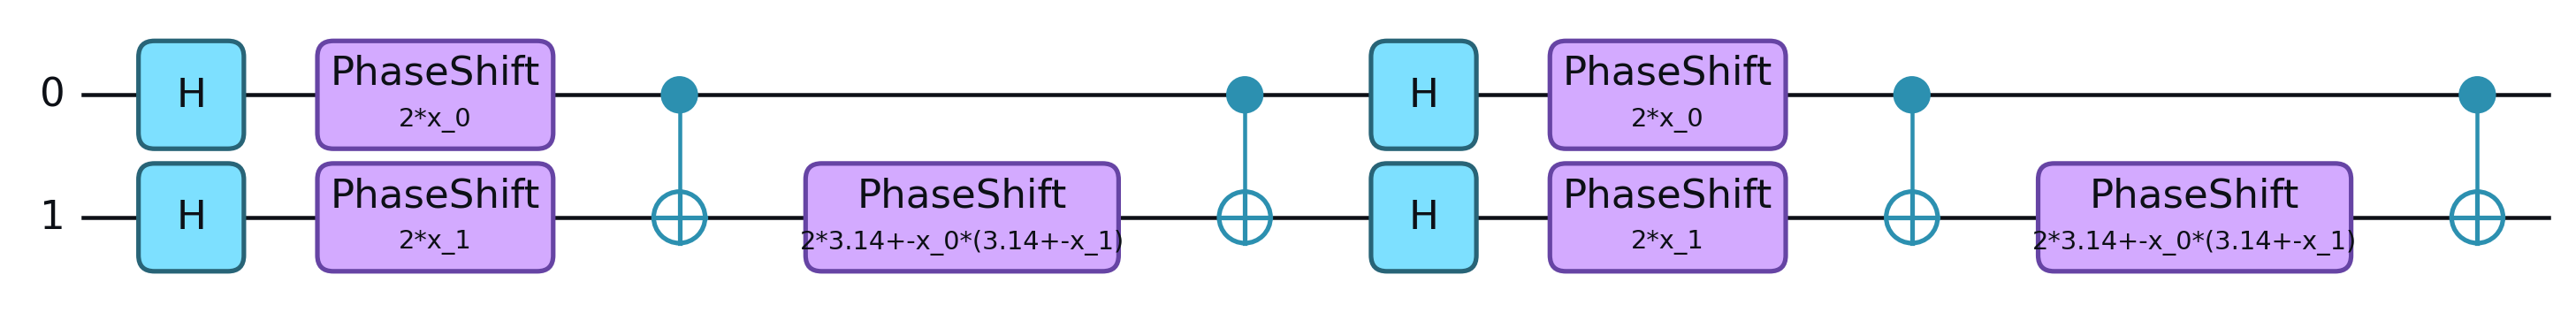

In [19]:
from eigenkit.core.ir import Constant, Multiply, Negate, Scale, Sum

PI = float(np.pi)


def zz_feature_map(reps=2, pairs=None):
    """Qiskit's ZZFeatureMap. `pairs` defaults to every pair of qubits."""

    def circuit(qc, x, w):
        n = len(x)
        edges = pairs if pairs is not None else [(a, b) for a in range(n) for b in range(a + 1, n)]
        for _ in range(reps):
            for q in range(n):
                qc.h(q)
                qc.phase_shift(Scale(x[q], 2.0), qubit=q)
            for a, b in edges:
                angle = 2.0 * (np.pi - x[a]) * (np.pi - x[b])
                qc.cnot(a, b)
                qc.phase_shift(angle, qubit=b)
                qc.cnot(a, b)

    return circuit


zz_kernel = QuantumKernel(n_features=N_QUBITS, feature_map=zz_feature_map(reps=2))
fig, ax = zz_kernel.draw_mpl(style="eigen")
fig

In [20]:
zz_model = QSVC(kernel=zz_kernel).fit(X_train, y_train)
print(f"ZZ kernel    validation {zz_model.score(X_val, y_val):.3f}   test {zz_model.score(X_test, y_test):.3f}")
print(f"Angle kernel validation {qsvc.score(X_val, y_val):.3f}   test {qsvc.score(X_test, y_test):.3f}")

ZZ kernel    validation 0.720   test 0.710
Angle kernel validation 0.610   test 0.575


More entanglement did not buy accuracy in this case.

### Training the kernel

So far the kernel had no free parameters. A **variational kernel** has trainable weights $\theta$ in its feature map, and we choose them to maximise the **kernel-target alignment** (KTA),

$$
\mathrm{KTA}(\theta) = \frac{\langle K_\theta, Y\rangle_F}{\|K_\theta\|_F\,\|Y\|_F}, \qquad Y_{ij} = \begin{cases} +1 & y_i = y_j \\ -1 & y_i \neq y_j \end{cases}
$$

the cosine similarity between the kernel matrix and the "ideal" kernel of the labels: it is 1 when same-class points are maximally similar and different-class points orthogonal. It only needs the kernel matrix, no SVM fit, so each step is cheap. `align_kernel(..., loss="kta")` minimises $-\mathrm{KTA}$ with SPSA, which estimates the gradient from two random perturbations per step whatever the number of weights.

You can also train with `loss="svc"`: the optimal value of the SVM dual problem, an upper bound on the generalisation error that quantum kernel alignment minimises (Glick *et al.*, arXiv:2105.03406), at the cost of an SVM fit at every step. Exercise 3.1 compares the two.

The model we use is the following: one shared $R_Y(\theta)$ rotation on every qubit, then the ZZ feature map. SPSA is noisy by design, so `align_kernel` keeps the best iterate it visits. With a single weight we can also afford to plot the whole landscape and see where it went.

In [21]:
def trainable_zz_map(reps=2):
    zz = zz_feature_map(reps)

    def circuit(qc, x, w):
        for q in range(len(x)):
            qc.ry(w[0], qubit=q)  # one trainable angle, shared by every qubit
        zz(qc, x, w)

    return circuit


trainable_kernel = QuantumKernel(n_features=N_QUBITS, feature_map=trainable_zz_map(), n_weights=1)
iterates = []  # (theta, KTA) after every SPSA step
alignment = align_kernel(
    trainable_kernel, X_train, y_train, loss="kta", maxiter=25, initial_weights=[0.4],
    callback=lambda k, w, loss: iterates.append((w[0], -loss)),  # the loss is -KTA
)

print(f"theta: 0.400 -> {alignment.weights[0]:.3f}")
print(f"KTA:   {-alignment.initial_loss:.4f} -> {-alignment.loss:.4f}   ({alignment.n_evaluations} kernel matrices)")

theta: 0.400 -> -0.512
KTA:   0.0206 -> 0.0269   (86 kernel matrices)


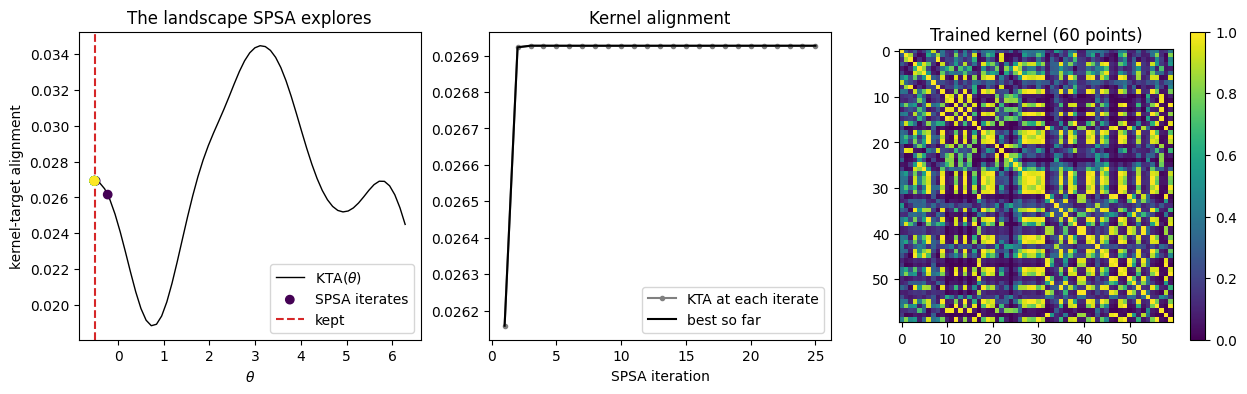

untrained (theta=0.4)  validation 0.680   test 0.660
trained                validation 0.710   test 0.695


In [22]:
from eigenkit.qml import kernel_target_alignment

# One weight, so we can afford to look at the whole landscape (it is 2*pi-periodic).
thetas = np.linspace(min(-0.5, min(t for t, _ in iterates)), max(2 * np.pi, max(t for t, _ in iterates)), 61)
landscape = [kernel_target_alignment(trainable_kernel.compute_kernel_matrix(X_train, weights=[t]), y_train) for t in thetas]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(thetas, landscape, "k-", lw=1, label="KTA$(\\theta)$")
axes[0].scatter(*zip(*iterates), c=range(len(iterates)), cmap="viridis", zorder=3, label="SPSA iterates")
axes[0].axvline(alignment.weights[0], color="tab:red", ls="--", label="kept")
axes[0].set_xlabel("$\\theta$")
axes[0].set_ylabel("kernel-target alignment")
axes[0].set_title("The landscape SPSA explores")
axes[0].legend()
history = -np.array(alignment.loss_history)
axes[1].plot(range(1, len(history) + 1), history, ".-", color="grey", label="KTA at each iterate")
axes[1].plot(range(1, len(history) + 1), np.maximum.accumulate(history), "k-", label="best so far")
axes[1].set_xlabel("SPSA iteration")
axes[1].set_title("Kernel alignment")
axes[1].legend()
order = np.argsort(y_train[:60], kind="stable")
im = axes[2].imshow(alignment.kernel.compute_kernel_matrix(X_train[:60][order]), vmin=0, vmax=1)
axes[2].set_title("Trained kernel (60 points)")
fig.colorbar(im, ax=axes[2])
plt.show()

for name, k in {"untrained (theta=0.4)": trainable_kernel.with_weights([0.4]), "trained": alignment.kernel}.items():
    model = QSVC(kernel=k).fit(X_train, y_train)
    print(f"{name:22s} validation {model.score(X_val, y_val):.3f}   test {model.score(X_test, y_test):.3f}")

### ⭐⭐ Exercise 3.1 — more parameters, more risk

Give the trainable kernel one weight **per qubit** (or per layer), align it, and compare **training** and **validation** accuracy before and after. Try both losses, `loss="svc"` and `loss="kta"` (kernel-target alignment). Does alignment ever overfit?

In [23]:
def per_qubit_map(reps=2):
    zz = zz_feature_map(reps)

    def circuit(qc, x, w):
        # TODO: one trainable RY(w[q]) per qubit, then the ZZ map
        for q in range(len(x)):
            qc.ry(w[q], qubit=q)  # one trainable weight per qubit
        zz(qc, x, w)

    return circuit


rich_kernel = QuantumKernel(n_features=N_QUBITS, feature_map=per_qubit_map(), n_weights=N_QUBITS)
start = np.full(N_QUBITS, 0.4)
for loss in ["svc", "kta"]:
    # TODO: align_kernel(...) from `start`, then compare train and validation accuracy
    # of QSVC(kernel=...) before and after.
    print(f"\n--- Aligning with loss='{loss}' ---")

    # Baseline (untrained)
    untrained_k = rich_kernel.with_weights(start)
    model_pre = QSVC(kernel=untrained_k).fit(X_train, y_train)
    print(f"Untrained - Train Acc: {model_pre.score(X_train, y_train):.3f} | Val Acc: {model_pre.score(X_val, y_val):.3f}")

    # Align
    alignment = align_kernel(rich_kernel, X_train, y_train, loss=loss, maxiter=25, initial_weights=start)

    # Evaluated (trained)
    model_post = QSVC(kernel=alignment.kernel).fit(X_train, y_train)
    print(f"Trained   - Train Acc: {model_post.score(X_train, y_train):.3f} | Val Acc: {model_post.score(X_val, y_val):.3f}")

    ...


--- Aligning with loss='svc' ---
Untrained - Train Acc: 0.670 | Val Acc: 0.680
Trained   - Train Acc: 0.671 | Val Acc: 0.700

--- Aligning with loss='kta' ---
Untrained - Train Acc: 0.670 | Val Acc: 0.680
Trained   - Train Acc: 0.661 | Val Acc: 0.670


### ⭐ Exercise 3.2 — design your own kernel

Write a new `circuit(qc, x, w)` and compare its validation accuracy with the maps above. Ideas:

* **IQP-style**: Hadamards, $R_Z(x_q)$, then $e^{-i x_a x_b Z_a Z_b}$ on each pair (`qc.pauli_exponential([("Z", a), ("Z", b)], Multiply(x[a], x[b]))`), repeated twice.
* **Re-uploading**: alternate data rotations and CNOTs several times.
* A different entangler: CZ (`qc.mcz(a, b)`) instead of CNOT.

In [24]:
def my_feature_map(qc, x, w):
    n = len(x)
    # TODO: add gates. For example a Hadamard layer, data rotations qc.rz(x[q], qubit=q),
    # and an entangler on each pair of qubits.

    # Two repetitions of an IQP-style circuit
    for _ in range(2):
        for q in range(n):
            qc.h(q)
            qc.rz(x[q], qubit=q)
        for a in range(n):
            for b in range(a + 1, n):
                # Entangler: e^(-i * x_a * x_b * Z_a * Z_b)
                qc.pauli_exponential([("Z", a), ("Z", b)], Multiply(x[a], x[b]))
    ...


my_kernel = QuantumKernel(n_features=N_QUBITS, feature_map=my_feature_map)
my_model = QSVC(kernel=my_kernel).fit(X_train, y_train)
print(f"my kernel validation accuracy: {my_model.score(X_val, y_val):.3f}")

my kernel validation accuracy: 0.710


## 4. Quantum vs classical benchmarking

A single train/test split and a weak baseline make any model look good. Let's find a meaningful comparison with classical benchmarks:

* use **strong, tuned** classical baselines, not a default linear SVM;
* repeat over several **random splits** and reports the spread;
* check whether a difference is larger than the **spread across splits**;
* use the **same preprocessing** for every model;
* report **cost** (time, circuits, shots) alongside accuracy.

`eigenkit.benchmark.compare` does the bookkeeping: each model is a full pipeline, refitted on 5 different splits of the dataset.

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from eigenkit.benchmark import compare

# Split bal_eiot into the format expected by eigenkit compare (a dictionary)
X_df = bal_eiot.iloc[:, :-1]
y_df = bal_eiot.iloc[:, -1]

X_tr, X_te, y_tr, y_te = train_test_split(X_df, y_df, test_size=0.2, random_state=42, stratify=y_df)

dataset_dict = {
    "X_train": X_tr,
    "y_train": y_tr,
    "X_test": X_te,
    "y_test": y_te
}

models = {
    "QSVC Angle": make_pipeline(make_preprocessing(), QSVC(feature_map="Angle", reps=1)),
    "QSVC AngleCNOT": make_pipeline(make_preprocessing(), QSVC(feature_map="AngleCNOT", reps=2)),
    "QSVC ZZ": make_pipeline(make_preprocessing(), QSVC(kernel=zz_kernel)),
    "SVC RBF (tuned)": make_pipeline(
        make_preprocessing(),
        GridSearchCV(SVC(), {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.1, 1]}, cv=5),
    ),
    "Logistic regression": make_pipeline(make_preprocessing(), LogisticRegression()),
    "Random forest": make_pipeline(make_preprocessing(), RandomForestClassifier(n_estimators=200, random_state=0)),
}

benchmark = compare(models, dataset=dataset_dict, n_seeds=5, test_size=0.2, validation_size=0.0)
print(benchmark.table())

┌─────────────────────┬───────────────┬───────────────┬───────────────┬──────────────────┐
│ Model               │ Accuracy      │ F1            │ Fit time (s)  │ Predict time (s) │
├─────────────────────┼───────────────┼───────────────┼───────────────┼──────────────────┤
│ QSVC Angle          │ 0.610 ± 0.000 │ 0.588 ± 0.000 │ 0.033 ± 0.019 │ 0.012 ± 0.0068   │
│ QSVC AngleCNOT      │ 0.610 ± 0.000 │ 0.588 ± 0.000 │ 0.034 ± 0.015 │ 0.011 ± 0.00078  │
│ QSVC ZZ             │ 0.705 ± 0.000 │ 0.704 ± 0.000 │ 0.043 ± 0.023 │ 0.018 ± 0.0089   │
│ SVC RBF (tuned)     │ 0.625 ± 0.000 │ 0.610 ± 0.000 │ 1.4 ± 0.43    │ 0.01 ± 0.0034    │
│ Logistic regression │ 0.585 ± 0.000 │ 0.577 ± 0.000 │ 0.038 ± 0.016 │ 0.0059 ± 0.002   │
│ Random forest       │ 0.754 ± 0.007 │ 0.754 ± 0.007 │ 0.62 ± 0.13   │ 0.026 ± 0.0069   │
└─────────────────────┴───────────────┴───────────────┴───────────────┴──────────────────┘


### How "quantum" was the `"Angle"` kernel?

The `"Angle"` map prepares a product state: qubit $q$ is $R_X(x_q)|0\rangle$. The overlap of two product states is the product of single-qubit overlaps, so

$$
K_{\text{Angle}}(x, x') = \prod_q \cos^2\!\Big(\frac{x_q - x'_q}{2}\Big),
$$

a classical kernel you can write in one line. Check it, and train a classical SVM with it.

In [26]:
def cosine_kernel(A, B):
    """The 'Angle' quantum kernel, computed classically."""
    return np.prod(np.cos((A[:, None, :] - B[None, :, :]) / 2) ** 2, axis=-1)


K_quantum = kernel.compute_kernel_matrix(X_train)
print("max |K_quantum - K_classical| =", np.abs(K_quantum - cosine_kernel(X_train, X_train)).max())

classical_twin = SVC(kernel=cosine_kernel).fit(X_train, y_train)
print(f"QSVC 'Angle'      test accuracy {qsvc.score(X_test, y_test):.3f}")
print(f"classical cosine  test accuracy {classical_twin.score(X_test, y_test):.3f}")

max |K_quantum - K_classical| = 8.881784197001252e-16
QSVC 'Angle'      test accuracy 0.575
classical cosine  test accuracy 0.575


Any claim of a quantum advantage has to survive this kind of check: if the kernel can be computed efficiently on a classical computer, the quantum computer is not needed. Entangling maps (ZZ, IQP) are believed hard to simulate at scale; at 2 qubits, everything is easy.

## Which simulator is fastest?

Imagine we want to calculate this kernel for a large dataset. As we've already seen that we do not need a quantum computer to compute this kernel, we will want to simulate the circuit classically. For this task, we can choose among many quantum simulators. Every provider computes the same kernel; what changes is speed. The library `eigenkit` allows you to change the provider by changing the parameter `provider=` and nothing else. It checks that all kernels agree, and times the Gram matrix of 150 samples as the circuit grows.

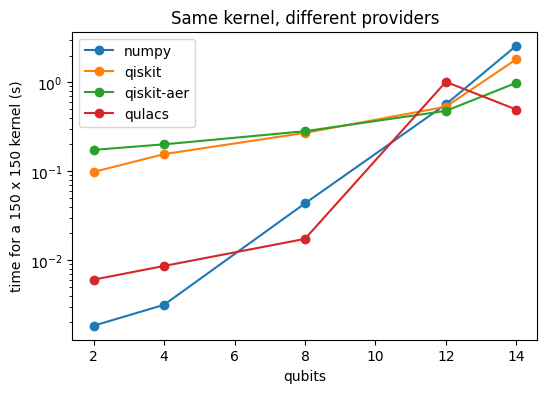

fastest provider by qubit count: {2: 'numpy', 4: 'numpy', 8: 'qulacs', 12: 'qiskit-aer', 14: 'qulacs'}


In [27]:
from eigenkit.benchmark import timer

providers = [p for p in ["numpy", "pennylane", "qiskit", "qiskit-aer", "qulacs"] if p in registered_names()]
qubit_counts = [2, 4, 8, 12, 14]
rng = np.random.default_rng(0)
timings = {p: [] for p in providers}

for n in qubit_counts:
    X_race = rng.uniform(0, np.pi, size=(150, n))
    reference = None
    for p in providers:
        race_kernel = QuantumKernel(n_features=n, feature_map="AngleCNOT", reps=2, provider=p)
        runs = []
        for _ in range(3):
            with timer() as t:
                K = race_kernel.compute_kernel_matrix(X_race)
            runs.append(t["elapsed"])
        reference = K if reference is None else reference
        assert np.abs(K - reference).max() < 1e-10, f"{p} disagrees"
        timings[p].append(np.median(runs))

plt.figure(figsize=(6, 4))
for p in providers:
    plt.semilogy(qubit_counts, timings[p], "o-", label=p)
plt.xlabel("qubits")
plt.ylabel("time for a 150 x 150 kernel (s)")
plt.title("Same kernel, different providers")
plt.legend()
plt.show()

fastest = pd.DataFrame(timings, index=qubit_counts).idxmin(axis=1)
print("fastest provider by qubit count:", fastest.to_dict())

## 5. From simulator to quantum hardware

A simulator applies any gate to any pair of qubits. A real device does not:

* it has a small **native gate set**: IBM Heron runs $\{CZ, R_Z, \sqrt{X}, X\}$, IQM runs $\{CZ, R(\theta, \phi)\}$;
* it has a **coupling map**: two-qubit gates only between connected qubits. IBM uses a *heavy-hex* lattice (each qubit has at most 3 neighbours); IQM Garnet a *square* lattice (up to 4); IQM's *star* devices route every interaction through a central resonator with MOVE operations;
* every gate and every measurement has an **error rate**.

**Transpilation** rewrites the circuit into native gates, picks physical qubits (*layout*) and inserts SWAPs where the circuit needs a connection the chip lacks (*routing*). The same `QuantumKernel` compiles for any target: only `provider=` changes. The *fake* devices below are local snapshots of real chips: same gates, same coupling map, a recorded noise model, no account needed.

**The kernel for this part.** Noise acts mostly through two-qubit gates. The 2-qubit ZZ kernel of Part 3 transpiles to only 6 of them, and the noise barely changes it. To see what hardware does to a kernel, this part uses a deeper version of the same ZZ map: 4 qubits and 3 repetitions, about 100 two-qubit gates once transpiled. Its bandwidth is small, `scale=0.1`, which keeps the kernel values on 4 qubits from concentrating (C2 and C3 come back to this). The transpilation, the noise study and your IBM run all use this kernel.

In [28]:
from iqm.qiskit_iqm import IQMFakeDeneb
from iqm.qiskit_iqm.fake_backends.fake_garnet import IQMFakeGarnet
from qiskit_ibm_runtime.fake_provider import FakeFez

fez, garnet, deneb = FakeFez(), IQMFakeGarnet(), IQMFakeDeneb()


def hardware_targets(shots=1000, optimization_level=3, seed=0):
    """The same compile settings for every device, so the comparison is fair."""
    targets = {
        "IBM Heron (fake ibm_fez)": QiskitRuntimeConfig(
            backend_instance=fez, primitive="sampler", shots=shots,
            optimization_level=optimization_level, seed_transpiler=seed,
        ),
        "IQM Garnet (fake)": IQMConfig(
            backend_instance=garnet, shots=shots, optimization_level=optimization_level, seed_transpiler=seed
        ),
        "IQM Deneb, star (fake)": IQMConfig(
            backend_instance=deneb, shots=shots, optimization_level=optimization_level, seed_transpiler=seed
        ),
    }
    if HAVE_IBM:
        targets[f"your IBM device ({BACKEND_NAME})"] = QiskitRuntimeConfig(
            backend_name=BACKEND_NAME, primitive="sampler", shots=shots,
            optimization_level=optimization_level, seed_transpiler=seed,
        )
    return targets


def resource_table(feature_map, n_features, targets):
    rows = []
    for name, config in targets.items():
        report = QuantumKernel(n_features=n_features, feature_map=feature_map, provider=config).circuit.resources()
        rows.append({
            "target": name,
            "device": report["backend_name"],
            "2q gates": report["n_2q_gates"],
            "of which routing": report["routing_overhead_2q"],
            "2q depth": report["depth_2q"],
            "depth": report["depth"],
            "physical qubits": report["physical_qubits"],
        })
    return pd.DataFrame(rows).set_index("target").round(3)

In [29]:
HW_QUBITS = 4
hw_preprocessing = make_preprocessing(HW_QUBITS).fit(X_train_raw)
Xh_train, Xh_test = hw_preprocessing.transform(X_train_raw), hw_preprocessing.transform(X_test_raw)


def hardware_kernel(provider="numpy"):
    """The ZZ map of Part 3 on 4 qubits, 3 repetitions, bandwidth 0.1, for any provider."""
    return QuantumKernel(n_features=HW_QUBITS, feature_map=zz_feature_map(reps=3), scale=0.1, provider=provider)


ideal_accuracy = QSVC(kernel=hardware_kernel()).fit(Xh_train, y_train).score(Xh_test, y_test)
print(f"ideal simulator, all the data: test accuracy {ideal_accuracy:.3f}")
resource_table(zz_feature_map(reps=3), HW_QUBITS, hardware_targets())

ideal simulator, all the data: test accuracy 0.630


/usr/local/lib/python3.13/dist-packages/eigenkit/qml/_kernels.py:594: CostWarning: Qiskit Runtime compile against 'ibm_fez' via sampler. Each run/submit will consume IBM Quantum compute time at shots=1000 (one job of 1 PUBs per call).
  self._inversion = Circuit(


,device,2q gates,of which routing,2q depth,depth,physical qubits
target,,,,,,
IBM Heron (fake ibm_fez),fake_fez,106,36,106,385,"[143, 144, 142, 136]"
IQM Garnet (fake),IQMFakeGarnetBackend,104,34,104,273,"[7, 8, 2, 12]"
"IQM Deneb, star (fake)",IQMFakeDenebBackend,142,72,142,244,"[0, 1, 2, 3]"
your IBM device (ibm_fez),ibm_fez,106,36,106,385,"[143, 136, 142, 144]"


whole circuit: {'rz': 204, 'sx': 183, 'cz': 106, 'measure': 4, 'barrier': 1}


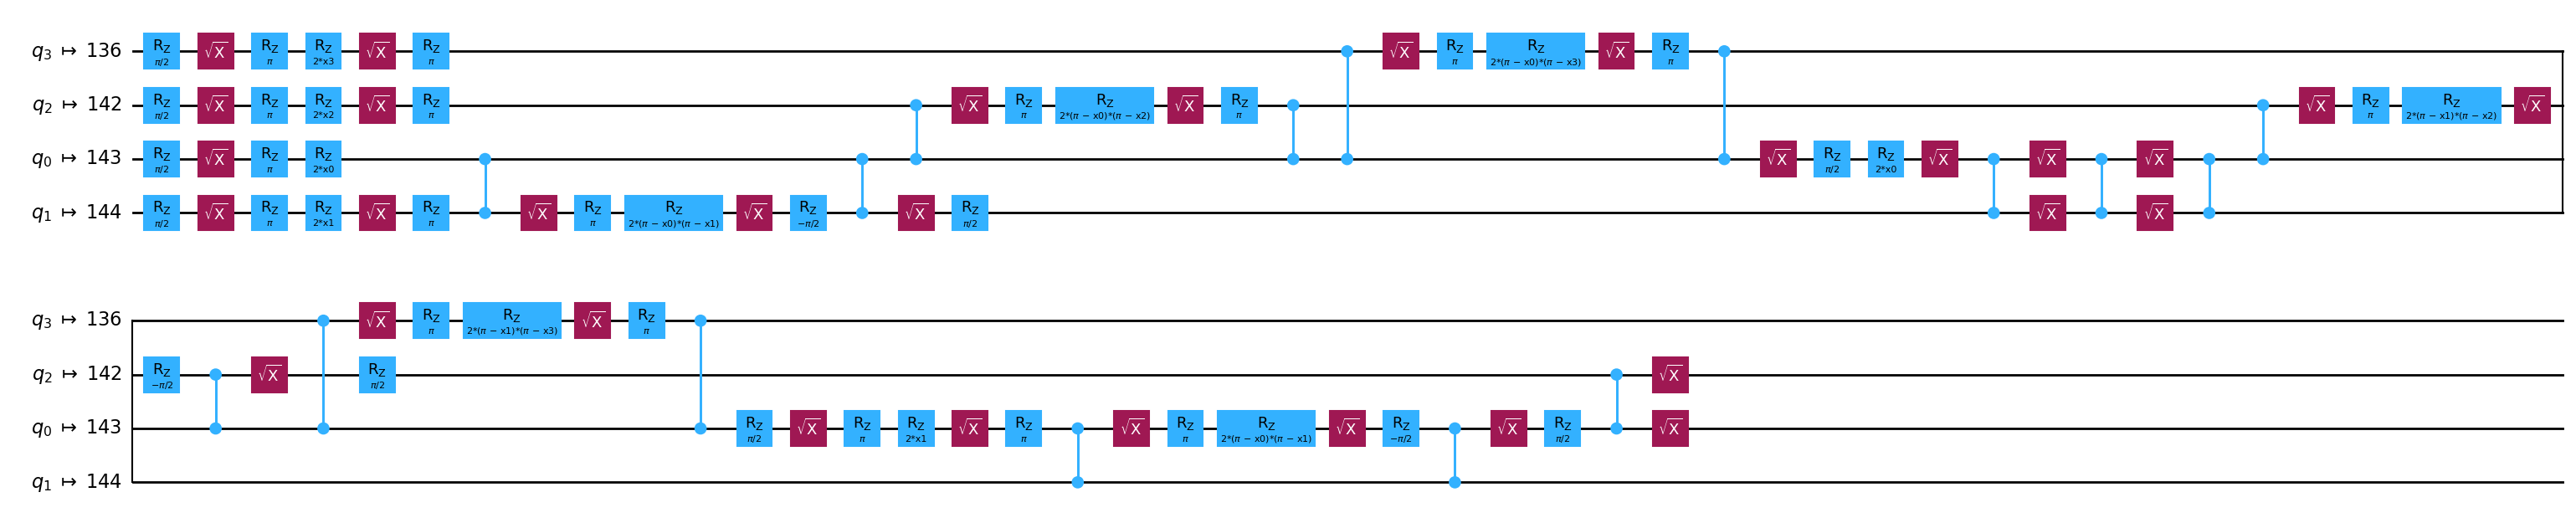

In [30]:
hw_view = hardware_kernel(hardware_targets()["IBM Heron (fake ibm_fez)"])
transpiled = hw_view.circuit.transpiled_circuit()
print("whole circuit:", dict(transpiled.count_ops()))

opening = transpiled.copy_empty_like()  # the first 90 of its ~500 operations, to keep the drawing readable
opening.global_phase = 0  # irrelevant for the measurement, and its label is very long
for instruction in transpiled.data[:90]:
    opening.append(instruction)
opening.draw("mpl", idle_wires=False, fold=45)

The counts are for the **inversion circuit** $U(x_i)U^\dagger(x_j)$, so roughly twice the feature map. The drawing shows the start of the circuit compiled for the fake `ibm_fez`: native gates only, on the physical qubits the transpiler picked.

### Noise

Fake devices also simulate their noise. Compute the hardware kernel on the ideal simulator, the fake IBM device and the fake IQM device, and use each kernel matrix in two ways: train and test the SVM on the same device, or train it on the ideal simulator and only test on the device. A noisy simulation is slow, so we use 20 training and 40 test points (about half a minute).

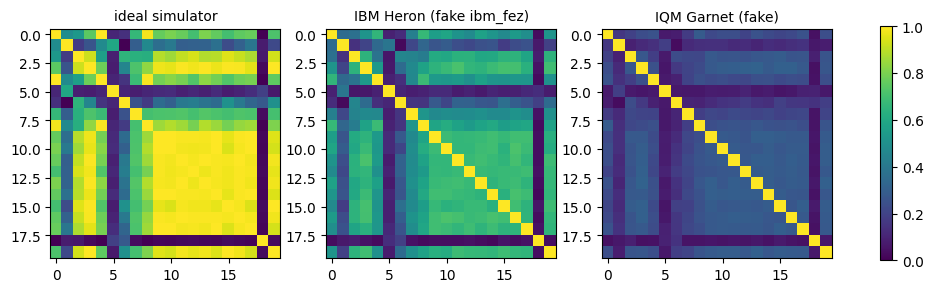

test accuracy on the 40 test points


,trained on this device,trained on the simulator
device,,
ideal simulator,0.600,0.600
IBM Heron (fake ibm_fez),0.575,0.575
IQM Garnet (fake),0.500,0.525


In [31]:
def stratified_subset(y, per_class, seed):
    """Indices of `per_class` random samples from each class."""
    # Convert to numpy array to ensure flatnonzero and positional indexing work seamlessly
    y_arr = np.asarray(y)
    rng = np.random.default_rng(seed)
    return np.sort(np.concatenate([rng.choice(np.flatnonzero(y_arr == c), per_class, replace=False) for c in (0, 1)]))


noise_train = stratified_subset(y_train, 10, seed=3)
noise_test = stratified_subset(y_test, 20, seed=4)

# Use .iloc or conversion to numpy array to prevent pandas label-based KeyError
Xn_train, yn_train = Xh_train[noise_train], y_train.iloc[noise_train].values
Xn_test, yn_test = Xh_test[noise_test], y_test.iloc[noise_test].values

noise_devices = {"ideal simulator": "numpy"} | {
    name: config for name, config in hardware_targets(shots=1000).items()
    if name in ("IBM Heron (fake ibm_fez)", "IQM Garnet (fake)")
}
kernels = {}
for name, provider in noise_devices.items():
    device_kernel = hardware_kernel(provider)
    kernels[name] = device_kernel.compute_kernel_matrix(Xn_train), device_kernel.compute_kernel_matrix(Xn_test, Xn_train)

K_ideal = kernels["ideal simulator"][0]
simulator_svm = SVC(kernel="precomputed").fit(K_ideal, yn_train)
off_diagonal_entries = np.triu_indices(len(K_ideal), k=1)
order = np.argsort(yn_train, kind="stable")
fig, axes = plt.subplots(1, len(kernels), figsize=(4.2 * len(kernels), 3.8))
rows = []
for ax, (name, (K_tr, K_te)) in zip(axes, kernels.items()):
    im = ax.imshow(K_tr[np.ix_(order, order)], vmin=0, vmax=1)
    ax.set_title(name, fontsize=10)
    rows.append({
        "device": name,
        "trained on this device": SVC(kernel="precomputed").fit(K_tr, yn_train).score(K_te, yn_test),
        "trained on the simulator": simulator_svm.score(K_te, yn_test),
    })
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()
print("test accuracy on the 40 test points")
pd.DataFrame(rows).set_index("device").round(3)

Noise pulls the off-diagonal entries towards the value of a fully mixed state ($1/2^n$), so the kernel matrix loses contrast: roughly $K \to aK + c$ with $a < 1$, and $a$ is smaller for deeper circuits.

* **Trained on the device**, the SVM barely notices. A uniform rescaling leaves its decisions unchanged (with $C \to C/a$). Accuracy drops only once the remaining contrast is comparable to the shot noise of each entry, $\sqrt{K(1-K)/S}$ for $S$ shots, or when the errors differ from circuit to circuit, as they do on real chips.
* **Trained on the simulator**, it does notice. Its decision function $f(x) = \sum_i \alpha_i y_i K(x, x_i) + b$ becomes $a\,\big(f(x) - b\big) + b$ on the device (the offset $c$ cancels, because $\sum_i \alpha_i y_i = 0$). The kernel term shrinks and the intercept $b$ does not, so the decision boundary moves and the points near it flip to the class that $b$ favours. The smaller $a$, the more points flip.

So a model has to be trained with the kernel it will be used with. With 40 test points, one point is 0.025 of accuracy. Fake-device noise models are snapshots of one calibration: treat the numbers as illustrations of *why* depth and routing matter, not as a ranking of vendors.

### Your own IBM run

Now the same ZZ kernel on a real IBM QPU, with your own account, on a small subset: 12 training and 12 test points, so 66 training entries (the diagonal is exactly 1 and the matrix is symmetric) and 144 test entries, submitted as **two jobs**.

Open Plan gives 10 QPU minutes per 28 days. Each shot costs roughly the device's repetition delay, a few hundred microseconds, so this run should use about a minute; check the job's usage on the IBM dashboard afterwards. Look at the cost first: nothing is submitted until you set `RUN_ON_HARDWARE = True`.

In [32]:
hw_train_idx = stratified_subset(y_train, 6, seed=1)
hw_test_idx = stratified_subset(y_test, 6, seed=2)
X_hw_train, y_hw_train = Xh_train[hw_train_idx], y_train.iloc[hw_train_idx]
X_hw_test, y_hw_test = Xh_test[hw_test_idx], y_test.iloc[hw_test_idx]
HW_SHOTS = 1000

if HAVE_IBM:
    hw_kernel = hardware_kernel(
        QiskitRuntimeConfig(
            backend_name=BACKEND_NAME, primitive="sampler", shots=HW_SHOTS,
            optimization_level=3, seed_transpiler=0,
        )
    )
    print("training kernel:", hw_kernel.estimate_cost(X_hw_train))
    print("test kernel:    ", hw_kernel.estimate_cost(X_hw_test, X_hw_train))
else:
    print("No saved IBM account: skip to the cell that loads the pre-run results.")

/usr/local/lib/python3.13/dist-packages/eigenkit/qml/_kernels.py:594: CostWarning: Qiskit Runtime compile against 'ibm_fez' via sampler. Each run/submit will consume IBM Quantum compute time at shots=1000 (one job of 1 PUBs per call).
  self._inversion = Circuit(


training kernel: {'method': 'inversion', 'n_circuits': 66, 'n_jobs': 1, 'shots': 1000, 'total_shots': 66000, 'n_2q_gates': 106, 'depth': 385, 'backend_name': 'ibm_fez'}
test kernel:     {'method': 'inversion', 'n_circuits': 144, 'n_jobs': 1, 'shots': 1000, 'total_shots': 144000, 'n_2q_gates': 106, 'depth': 385, 'backend_name': 'ibm_fez'}


In [33]:
RUN_ON_HARDWARE = True  # set to True, then run this cell once

if HAVE_IBM and RUN_ON_HARDWARE:
    job_train = hw_kernel.submit_kernel_matrix(X_hw_train)
    job_test = hw_kernel.submit_kernel_matrix(X_hw_test, X_hw_train)
    job_train.save("my_ibm_kernel_train.json")  # job id + layout, to collect it later
    job_test.save("my_ibm_kernel_test.json")
    print("submitted:", job_train.job_id(), job_test.job_id())

submitted: dc1h3uthdvas73bkqoq0 dc1h3vds2omc738ajof0


Open Plan jobs queue. Check the status, and when both are `DONE`, collect the matrices. If you restart the notebook in the meantime, re-attach with `hw_kernel.retrieve_kernel_matrix("my_ibm_kernel_train.json")`.

Current status: RUNNING RUNNING
Could not retrieve hardware results (AttributeError). Falling back to simulated noise.


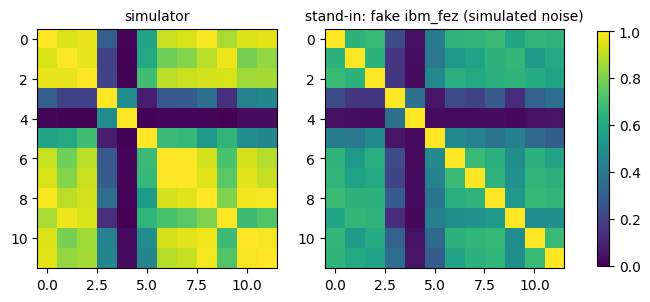

test accuracy on the 12 test points (trained on -> tested on)
  simulator -> simulator 0.583
  simulator -> hardware  0.583
  hardware  -> hardware  0.583


In [34]:
PRERUN = Path("data/ibm_kernel_prerun.npz")
KERNEL_ID = f"zz_feature_map(reps=3), scale 0.1, on {HW_QUBITS} principal components"  # what a pre-run must match

use_fallback=True
if HAVE_IBM and RUN_ON_HARDWARE:
  try:
        # Check status first to avoid waiting indefinitely if still queued
        print("Current status:", job_train.status(), job_test.status())
        if job_train.status().name in ['RUNNING', 'QUEUED'] or job_test.status().name in ['RUNNING', 'QUEUED']:
            print("Jobs are still in the IBM queue. Falling back to the simulated noisy device for now...")
        else:
            K_hw_train = job_train.result(timeout=10)
            K_hw_test = job_test.result(timeout=10)
            hw_label = f"your run on {hw_kernel.circuit.resources()['backend_name']}"
            use_fallback = False
  except Exception as e:
        print(f"Could not retrieve hardware results ({type(e).__name__}). Falling back to simulated noise.")

if use_fallback:
    if PRERUN.exists() and str(np.load(PRERUN)["kernel"]) == KERNEL_ID:
        prerun = np.load(PRERUN, allow_pickle=False)
        K_hw_train, K_hw_test = prerun["K_train"], prerun["K_test"]
        hw_label = f"pre-run on {prerun['backend_name']} ({prerun['created']})"
    else:
        # No hardware data ready yet: a noisy fake device stands in.
        stand_in = hardware_kernel(hardware_targets(shots=HW_SHOTS)["IBM Heron (fake ibm_fez)"])
        K_hw_train = stand_in.compute_kernel_matrix(X_hw_train)
        K_hw_test = stand_in.compute_kernel_matrix(X_hw_test, X_hw_train)
        hw_label = "stand-in: fake ibm_fez (simulated noise)"


ideal_hw = hardware_kernel()
K_sim_train = ideal_hw.compute_kernel_matrix(X_hw_train)
K_sim_test = ideal_hw.compute_kernel_matrix(X_hw_test, X_hw_train)

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.8))
for ax, K, title in ((axes[0], K_sim_train, "simulator"), (axes[1], K_hw_train, hw_label)):
    im = ax.imshow(K, vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

print("test accuracy on the 12 test points (trained on -> tested on)")
for trained_on, tested_on, (Ktr, Kte) in (
    ("simulator", "simulator", (K_sim_train, K_sim_test)),
    ("simulator", "hardware", (K_sim_train, K_hw_test)),
    ("hardware", "hardware", (K_hw_train, K_hw_test)),
):
    svm = SVC(kernel="precomputed").fit(Ktr, y_hw_train)
    print(f"  {trained_on:9s} -> {tested_on:9s} {svm.score(Kte, y_hw_test):.3f}")

In [ ]:
PRERUN = Path("data/ibm_kernel_prerun.npz")
KERNEL_ID = f"zz_feature_map(reps=3), scale 0.1, on {HW_QUBITS} principal components"  # what a pre-run must match

if HAVE_IBM and RUN_ON_HARDWARE:
    print("status:", job_train.status(), job_test.status())
    K_hw_train, K_hw_test = job_train.result(), job_test.result()  # waits for the jobs
    hw_label = f"your run on {hw_kernel.circuit.resources()['backend_name']}"
elif PRERUN.exists() and str(np.load(PRERUN)["kernel"]) == KERNEL_ID:
    prerun = np.load(PRERUN, allow_pickle=False)
    K_hw_train, K_hw_test = prerun["K_train"], prerun["K_test"]
    hw_label = f"pre-run on {prerun['backend_name']} ({prerun['created']})"
else:
    # No hardware data for this kernel yet: a noisy fake device stands in.
    stand_in = hardware_kernel(hardware_targets(shots=HW_SHOTS)["IBM Heron (fake ibm_fez)"])
    K_hw_train = stand_in.compute_kernel_matrix(X_hw_train)
    K_hw_test = stand_in.compute_kernel_matrix(X_hw_test, X_hw_train)
    hw_label = "stand-in: fake ibm_fez (simulated noise)"

ideal_hw = hardware_kernel()
K_sim_train = ideal_hw.compute_kernel_matrix(X_hw_train)
K_sim_test = ideal_hw.compute_kernel_matrix(X_hw_test, X_hw_train)

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.8))
for ax, K, title in ((axes[0], K_sim_train, "simulator"), (axes[1], K_hw_train, hw_label)):
    im = ax.imshow(K, vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

print("test accuracy on the 12 test points (trained on -> tested on)")
for trained_on, tested_on, (Ktr, Kte) in (
    ("simulator", "simulator", (K_sim_train, K_sim_test)),
    ("simulator", "hardware", (K_sim_train, K_hw_test)),
    ("hardware", "hardware", (K_hw_train, K_hw_test)),
):
    svm = SVC(kernel="precomputed").fit(Ktr, y_hw_train)
    print(f"  {trained_on:9s} -> {tested_on:9s} {svm.score(Kte, y_hw_test):.3f}")

## 6. ⭐⭐⭐ Challenges

Open problems, for the fast and the curious.

### C1. Hardware-native kernels

Two-qubit gates are the main source of error, and every interaction your feature map needs between qubits the chip does not connect costs extra SWAPs. So: **design the entangling pattern of a kernel to match the hardware.**

Take 6 qubits (6 principal components) and an Ising-type feature map: Hadamards, $R_Z(x_q)$ on every qubit, then $e^{-i x_a x_b Z_aZ_b}$ on a chosen set of **edges** $(a, b)$. Build three designs:

1. **heavy-hex native**: a path $0-1-2-3-4-5$, which exists on IBM's heavy-hex lattice;
2. **square-lattice native**: a $2\times3$ grid, edges $(0,1),(1,2),(3,4),(4,5),(0,3),(1,4),(2,5)$. It contains 4-cycles, which heavy-hex does not have and Garnet's square lattice does;
3. **all-to-all**: every pair, the hardware-agnostic default.

Transpile every design for every device (fake `ibm_fez`, IQM Garnet, IQM Deneb) and compare: two-qubit gates, routing overhead, two-qubit depth. Then compare what the designs buy you: the validation accuracy of a QSVC trained on the ideal simulator and on each noisy device.

*Questions*: Does each native design win on its own hardware and lose elsewhere? What does the star topology do to every design? Is the more expressive all-to-all map worth its cost?

*Tools*: `resource_table(...)` and `hardware_targets()` from Part 5; `fez.coupling_map`, `garnet.coupling_map`; `rustworkx.is_subgraph_isomorphic` to check that a design embeds in a chip.

In [35]:
import rustworkx as rx

N_C1 = 6
prep6 = make_preprocessing(N_C1).fit(X_train_raw)
X6_train, X6_val = prep6.transform(X_train_raw), prep6.transform(X_val_raw)


def ising_feature_map(edges, reps=1):
    def circuit(qc, x, w):
        for _ in range(reps):
            for q in range(len(x)):
                qc.h(q)
                qc.rz(x[q], qubit=q)
            for a, b in edges:
                qc.pauli_exponential([("Z", a), ("Z", b)], Multiply(x[a], x[b]))

    return circuit


designs = {
    #"path (heavy-hex native)": ...,  # TODO: list of (a, b) edges
    "path (heavy-hex native)": [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5)],
    #"2x3 grid (square native)": ...,  # TODO
    "2x3 grid (square native)": [(0, 1), (1, 2), (3, 4), (4, 5), (0, 3), (1, 4), (2, 5)],
    #"all-to-all": ...,  # TODO
    "all-to-all": [(a, b) for a in range(N_C1) for b in range(a + 1, N_C1)],
}

# TODO: for each design, resource_table(ising_feature_map(edges), N_C1, targets)
# with targets = hardware_targets() minus your real device, and compare.
targets = hardware_targets()
if f"your IBM device ({BACKEND_NAME})" in targets:
    targets.pop(f"your IBM device ({BACKEND_NAME})")

for name, edges in designs.items():
    print(f"=== Resources for design: {name} ===")
    display(resource_table(ising_feature_map(edges), N_C1, targets))
    print("\n")

=== Resources for design: path (heavy-hex native) ===


,device,2q gates,of which routing,2q depth,depth,physical qubits
target,,,,,,
IBM Heron (fake ibm_fez),fake_fez,18,0,18,92,"[141, 142, 143, 136, 123, 124]"
IQM Garnet (fake),IQMFakeGarnetBackend,18,0,18,61,"[8, 3, 4, 9, 10, 5]"
"IQM Deneb, star (fake)",IQMFakeDenebBackend,36,18,36,71,"[2, 0, 1, 3, 4, 5]"




=== Resources for design: 2x3 grid (square native) ===


,device,2q gates,of which routing,2q depth,depth,physical qubits
target,,,,,,
IBM Heron (fake ibm_fez),fake_fez,40,18,22,91,"[143, 136, 125, 123, 124, 126]"
IQM Garnet (fake),IQMFakeGarnetBackend,22,0,10,37,"[8, 3, 0, 9, 4, 1]"
"IQM Deneb, star (fake)",IQMFakeDenebBackend,48,26,48,86,"[2, 0, 3, 4, 1, 5]"




=== Resources for design: all-to-all ===


,device,2q gates,of which routing,2q depth,depth,physical qubits
target,,,,,,
IBM Heron (fake ibm_fez),fake_fez,96,38,79,243,"[125, 124, 126, 117, 123, 136]"
IQM Garnet (fake),IQMFakeGarnetBackend,86,28,78,197,"[3, 0, 4, 8, 2, 1]"
"IQM Deneb, star (fake)",IQMFakeDenebBackend,108,50,108,190,"[0, 1, 2, 3, 4, 5]"


In [ ]:
designs = {
    "path (heavy-hex native)": [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5)],
    "2x3 grid (square native)": [(0, 1), (1, 2), (3, 4), (4, 5), (0, 3), (1, 4), (2, 5)],
    "all-to-all": [(a, b) for a in range(N_C1) for b in range(a + 1, N_C1)],
}

targets = hardware_targets()
if f"your IBM device ({BACKEND_NAME})" in targets:
    targets.pop(f"your IBM device ({BACKEND_NAME})")

for name, edges in designs.items():
    print(f"=== Resources for design: {name} ===")
    display(resource_table(ising_feature_map(edges), N_C1, targets))
    print("\n")

In [36]:
# Noisy simulation runs every circuit (a minute or two): 16 training and 16 validation points.
c1_train = stratified_subset(y_train, 8, seed=5)
c1_val = stratified_subset(y_val, 8, seed=6)
# TODO: for each design, the accuracy on X6_val[c1_val] of a QSVC trained on X6_train[c1_train]
# with the ideal kernel and with each noisy device:
#   QSVC(kernel=QuantumKernel(n_features=N_C1, feature_map=ising_feature_map(edges), provider=...))

In [37]:
results = []

# Extract training and validation sets
X6_tr_subset = X6_train[c1_train]
y6_tr_subset = y_train.iloc[c1_train].values
X6_val_subset = X6_val[c1_val]
y6_val_subset = y_val.iloc[c1_val].values

# We will use the same noisy simulation devices as Part 5 (ideal, fake ibm_fez, fake garnet, fake deneb)
noise_targets = {
    "ideal": "numpy",
    "IBM Fez (fake)": hardware_targets()["IBM Heron (fake ibm_fez)"],
    "IQM Garnet (fake)": hardware_targets()["IQM Garnet (fake)"],
    "IQM Deneb (fake)": hardware_targets()["IQM Deneb, star (fake)"]
}

for design_name, edges in designs.items():
    for device_name, provider in noise_targets.items():
        # Create the specific kernel for this design and provider
        kernel = QuantumKernel(n_features=N_C1, feature_map=ising_feature_map(edges), provider=provider)

        # Train the QSVC model
        qsvc = QSVC(kernel=kernel).fit(X6_tr_subset, y6_tr_subset)

        # Evaluate on the validation set
        val_acc = qsvc.score(X6_val_subset, y6_val_subset)

        results.append({
            "Design": design_name,
            "Device": device_name,
            "Validation Accuracy": val_acc
        })

# Display the results in a formatted DataFrame
df_results = pd.DataFrame(results)
display(df_results.pivot(index="Design", columns="Device", values="Validation Accuracy"))

Device,IBM Fez (fake),IQM Deneb (fake),IQM Garnet (fake),ideal
Design,,,,
2x3 grid (square native),0.6250,0.5625,0.5625,0.5625
all-to-all,0.5625,0.4375,0.6250,0.3750
path (heavy-hex native),0.3750,0.3750,0.4375,0.3750


### C2. Exponential concentration

For expressive feature maps on many qubits, almost every pair of states is nearly orthogonal: the off-diagonal kernel values concentrate exponentially around a constant, the Gram matrix approaches the identity, and the SVM learns nothing (Thanasilp *et al.*, *Nat. Commun.* 15, 5200 (2024)). On hardware it is worse: resolving values that are all nearly equal needs exponentially many shots.

Plot the variance of the off-diagonal kernel values against the number of qubits, from 2 to 14, for the ZZ feature map of Part 3. What would a 50-qubit version of this kernel look like?

Tip: `provider="qulacs"` is the fastest simulator above ~6 qubits (Part 4).

In [ ]:
def off_diagonal(K):
    return K[np.triu_indices(len(K), k=1)]


qubit_range = [2, 4, 6, 8, 10, 12, 14]
variances = []
for n in qubit_range:
    Xn = make_preprocessing(n).fit(X_train_raw).transform(X_train_raw)[:120]
    # TODO: the kernel matrix of Xn with QuantumKernel(n_features=n, feature_map=zz_feature_map(reps=2)),
    # then append the variance of its off-diagonal values.
    ...

# TODO: plot the variances against qubit_range (a log scale helps).

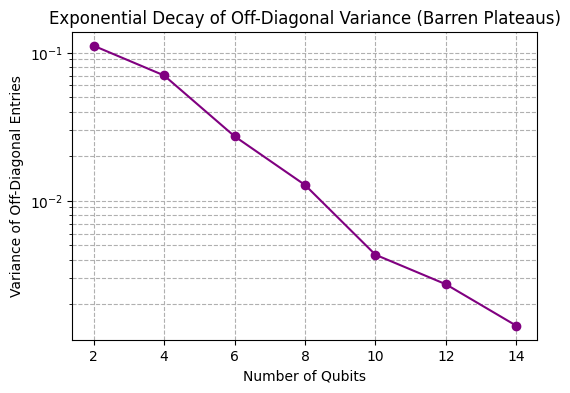

In [38]:
def off_diagonal(K):
    return K[np.triu_indices(len(K), k=1)]

qubit_range = [2, 4, 6, 8, 10, 12, 14]
variances = []

for n in qubit_range:
    # Preprocess and select 120 samples
    Xn = make_preprocessing(n).fit(X_train_raw).transform(X_train_raw)[:120]

    # Use the fastest simulator above 6 qubits (qulacs)
    kernel_n = QuantumKernel(n_features=n, feature_map=zz_feature_map(reps=2), provider="qulacs")
    K = kernel_n.compute_kernel_matrix(Xn)

    # Compute the variance of the off-diagonal entries
    var_val = np.var(off_diagonal(K))
    variances.append(var_val)

# Plot the variances against the number of qubits on a semi-log scale
plt.figure(figsize=(6, 4))
plt.semilogy(qubit_range, variances, "o-", color="purple")
plt.xlabel("Number of Qubits")
plt.ylabel("Variance of Off-Diagonal Entries")
plt.title("Exponential Decay of Off-Diagonal Variance (Barren Plateaus)")
plt.grid(True, which="both", ls="--")
plt.show()

In [39]:
from scipy.linalg import sqrtm
from sklearn.metrics.pairwise import rbf_kernel
from eigenkit.datasets import generate_ad_hoc

def geometric_difference(K_c, K_q, lam=1e-3):
    # Normalize kernels to trace N
    N = len(K_c)
    K_c_norm = K_c * (N / np.trace(K_c))
    K_q_norm = K_q * (N / np.trace(K_q))

    # Compute sqrt(K_q)
    sqrt_K_q = sqrtm(K_q_norm)

    # Compute (K_c + lam * I)^-1
    inv_term = np.linalg.inv(K_c_norm + lam * np.eye(N))

    # Compute the matrix product
    matrix_product = sqrt_K_q @ inv_term @ sqrt_K_q

    # Get the largest eigenvalue (spectral norm)
    eigenvalues = np.linalg.eigvalsh(matrix_product)
    max_eigenvalue = np.max(eigenvalues)

    return np.sqrt(max_eigenvalue)

In [40]:
N_C3 = 100
# 1. EdgeIIoT dataset
X_bc = make_preprocessing(3).fit(X_train_raw).transform(X_train_raw)[:N_C3]
y_bc = y_train[:N_C3].values

# 2. Ad Hoc dataset
X_ah, y_ah = generate_ad_hoc(n_samples=N_C3, n_qubits=3, random_state=0)

for dataset_name, X_data, y_data, scale in [
    ("bin_EIIoT", X_bc, y_bc, 0.2),
    ("ad hoc", X_ah, y_ah, 1.0)
]:
    print(f"\n=== Dataset: {dataset_name} (N = {N_C3}, sqrt(N) = {np.sqrt(N_C3):.2f}) ===")

    # Classically compute the equivalent of gamma='scale'
    gamma_scale = 1.0 / (X_data.shape[1] * X_data.var())

    # Compute Kernel Matrices
    K_rbf = rbf_kernel(X_data, gamma=gamma_scale)

    angle_k = QuantumKernel(n_features=3, feature_map="Angle", reps=1)
    K_angle = angle_k.compute_kernel_matrix(X_data)

    zz_k = QuantumKernel(n_features=3, feature_map=zz_feature_map(reps=2), scale=scale)
    K_zz = zz_k.compute_kernel_matrix(X_data)

    # Geometric Differences
    g_angle = geometric_difference(K_rbf, K_angle)
    g_zz = geometric_difference(K_rbf, K_zz)
    print(f"g(RBF || Angle): {g_angle:.3f}")
    print(f"g(RBF || ZZ):    {g_zz:.3f}")

    # Train & Evaluate SVM on first 70 train, last 30 test
    X_tr, X_te = X_data[:70], X_data[70:]
    y_tr, y_te = y_data[:70], y_data[70:]

    for k_name, k_obj in [("RBF", None), ("Angle", angle_k), ("ZZ", zz_k)]:
        if k_name == "RBF":
            clf = SVC(kernel="rbf", gamma=gamma_scale).fit(X_tr, y_tr)
            acc = clf.score(X_te, y_te)
        else:
            # Precomputed train and test matrices relative to the split
            K_tr = k_obj.compute_kernel_matrix(X_tr)
            K_te = k_obj.compute_kernel_matrix(X_te, X_tr)
            clf = SVC(kernel="precomputed").fit(K_tr, y_tr)
            acc = clf.score(K_te, y_te)
        print(f"  Accuracy with {k_name:5s} Kernel: {acc:.3f}")


=== Dataset: bin_EIIoT (N = 100, sqrt(N) = 10.00) ===
g(RBF || Angle): 1.095
g(RBF || ZZ):    13.872
  Accuracy with RBF   Kernel: 0.667
  Accuracy with Angle Kernel: 0.633
  Accuracy with ZZ    Kernel: 0.600

=== Dataset: ad hoc (N = 100, sqrt(N) = 10.00) ===
g(RBF || Angle): 7.259
g(RBF || ZZ):    47.924
  Accuracy with RBF   Kernel: 0.500
  Accuracy with Angle Kernel: 0.600
  Accuracy with ZZ    Kernel: 1.000


### C3. Is there room for an advantage here?

Huang *et al.* (*Nat. Commun.* 12, 2631 (2021)) compare two kernels on the same inputs with the **geometric difference**

$$
g(K_C \| K_Q) = \sqrt{\big\|\sqrt{K_Q}\,(K_C + \lambda I)^{-1}\sqrt{K_Q}\big\|_\infty},
$$

where both kernel matrices are normalised to trace $N$ and $\|\cdot\|_\infty$ is the largest eigenvalue. The small $\lambda$ (we use $10^{-3}$) is needed because $K_C$ is numerically singular: an RBF Gram matrix has eigenvalues down to $10^{-10}$ and below, and inverting it exactly turns $g$ into a measure of round-off error.

How to read $g$: it depends only on the inputs and the two kernels, **not on the labels**. Close to 1, the classical kernel can learn any labelling the quantum one can, with about as much data. Of order $\sqrt{N}$ or larger ($N$ training points), there are labellings the quantum kernel learns from far fewer samples: room for an advantage, not a promise of one.

1. On 100 breast-cancer points (3 principal components, so 3 qubits), compute $g$ between an RBF kernel and two quantum kernels, `"Angle"` and the ZZ map, and compare with $\sqrt{N}$. On these data the ZZ map needs a smaller bandwidth, `QuantumKernel(..., scale=0.2)`, which multiplies the inputs by 0.2 before encoding them: at full bandwidth its kernel values on 3 qubits are already concentrated (C2) and the SVM is at chance.
2. Repeat on the **ad hoc dataset** of Havlíček *et al.* (`generate_ad_hoc(n_qubits=3)`), whose labels were generated by the ZZ feature map itself, at full bandwidth (`scale=1`).
3. Train an SVM with each kernel on each dataset and compare the test accuracies. The ZZ kernel wins on only one dataset: what does $g$ tell you about why?

In [41]:
from scipy.linalg import sqrtm
from sklearn.metrics.pairwise import rbf_kernel
from eigenkit.datasets import generate_ad_hoc

def geometric_difference(K_c, K_q, lam=1e-3):
  # TODO: normalise both kernels to trace N, then return
    # sqrt(largest eigenvalue of sqrt(K_q) (K_c + lam * I)^-1 sqrt(K_q))
    ...
    # Normalise both kernels to trace N
    N = len(K_c)
    K_c_norm = K_c * (N / np.trace(K_c))
    K_q_norm = K_q * (N / np.trace(K_q))

    # Compute sqrt(K_q)
    sqrt_K_q = sqrtm(K_q_norm)

    # Compute (K_c + lam * I)^-1
    inv_term = np.linalg.inv(K_c_norm + lam * np.eye(N))

    # Compute the matrix product inside the norm
    matrix_product = sqrt_K_q @ inv_term @ sqrt_K_q

    # Get the largest eigenvalue
    eigenvalues = np.linalg.eigvalsh(matrix_product)
    max_eigenvalue = np.max(eigenvalues)

    return np.sqrt(max_eigenvalue)

N_C3 = 100
# 1. Edge IIoT dataset (bin_EIIoT preprocess to 3 dimensions)
X_bc = make_preprocessing(3).fit(X_train_raw).transform(X_train_raw)[:N_C3]
y_bc = y_train[:N_C3].values

# 2. Ad Hoc dataset
X_ah, y_ah = generate_ad_hoc(n_samples=N_C3, n_qubits=3, random_state=0)

ZZ_SCALE = {"bin_EIIoT": 0.2, "ad hoc": 1.0}

#ZZ bandwidth that works for each dataset
# TODO: for each dataset, the RBF, "Angle" and ZZ (scale=ZZ_SCALE[dataset]) kernel matrices; g(RBF || kernel);
# and the test accuracy of SVC(kernel="precomputed") trained on the first 70 points.

for dataset_name, X_data, y_data in [
    ("bin_EIIoT", X_bc, y_bc),
    ("ad hoc", X_ah, y_ah)
]:
    print(f"\n=== Dataset: {dataset_name} (N = {N_C3}, sqrt(N) = {np.sqrt(N_C3):.2f}) ===")

    # Classical scale equivalent for RBF
    gamma_scale = 1.0 / (X_data.shape[1] * X_data.var())
    K_rbf = rbf_kernel(X_data, gamma=gamma_scale)

    angle_k = QuantumKernel(n_features=3, feature_map="Angle", reps=1)
    K_angle = angle_k.compute_kernel_matrix(X_data)

    scale = ZZ_SCALE[dataset_name]
    zz_k = QuantumKernel(n_features=3, feature_map=zz_feature_map(reps=2), scale=scale)
    K_zz = zz_k.compute_kernel_matrix(X_data)

    # Calculate Geometric Differences
    g_angle = geometric_difference(K_rbf, K_angle)
    g_zz = geometric_difference(K_rbf, K_zz)
    print(f"g(RBF || Angle): {g_angle:.3f}")
    print(f"g(RBF || ZZ):    {g_zz:.3f}")

    # Train & Evaluate SVM
    X_tr, X_te = X_data[:70], X_data[70:]
    y_tr, y_te = y_data[:70], y_data[70:]

    for k_name, k_obj in [("RBF", None), ("Angle", angle_k), ("ZZ", zz_k)]:
        if k_name == "RBF":
            clf = SVC(kernel="rbf", gamma=gamma_scale).fit(X_tr, y_tr)
            acc = clf.score(X_te, y_te)
        else:
            K_tr = k_obj.compute_kernel_matrix(X_tr)
            K_te = k_obj.compute_kernel_matrix(X_te, X_tr)
            clf = SVC(kernel="precomputed").fit(K_tr, y_tr)
            acc = clf.score(K_te, y_te)
        print(f"  Accuracy with {k_name:5s} Kernel: {acc:.3f}")


=== Dataset: bin_EIIoT (N = 100, sqrt(N) = 10.00) ===
g(RBF || Angle): 1.095
g(RBF || ZZ):    13.872
  Accuracy with RBF   Kernel: 0.667
  Accuracy with Angle Kernel: 0.633
  Accuracy with ZZ    Kernel: 0.600

=== Dataset: ad hoc (N = 100, sqrt(N) = 10.00) ===
g(RBF || Angle): 7.259
g(RBF || ZZ):    47.924
  Accuracy with RBF   Kernel: 0.500
  Accuracy with Angle Kernel: 0.600
  Accuracy with ZZ    Kernel: 1.000


## Discussion

*Your conclusions:*

* Which design choice had the largest effect on accuracy: qubit count, feature map, depth, bandwidth or training?
* Was the quantum kernel better than the tuned classical baseline? Was the comparison fair, and what would make it fairer?
* What changed between the simulator and the QPU: gates, depth, noise, cost, queue time?
* What would a convincing *practical* quantum advantage in kernel methods need: what kind of data, how many qubits, what error rates?